In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

In [3]:
diamond = sns.load_dataset("diamonds")
diamond.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


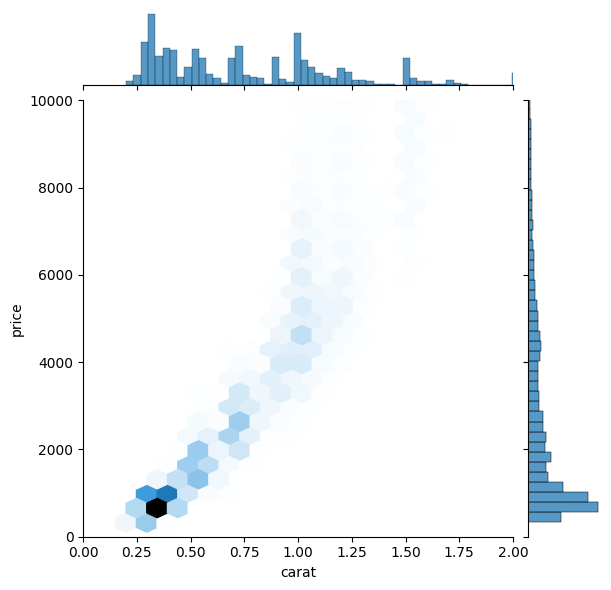

In [13]:
#Hexbin Plot
sns.jointplot( x = "carat", y = "price", kind = "hex", data = diamond)
#zoom in
plt.xlim(0,2)
plt.ylim(0,10000)
plt.show()

<Axes: xlabel='cut', ylabel='clarity'>

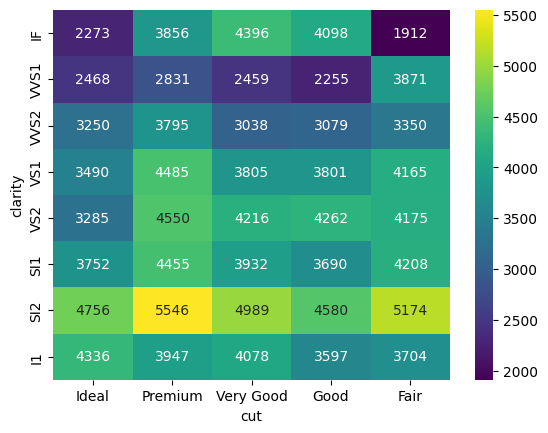

In [9]:
#Heatmap -> Pivot Table avg price by cut & clarity
diamond_price_pivot = pd.pivot_table(data = diamond, values = "price", index = "clarity", columns = "cut", aggfunc = "mean")
sns.heatmap(diamond_price_pivot, annot = True, fmt = ".0f", cmap = "viridis")

In [17]:
df = sns.load_dataset("diamonds")
df.head(10)

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75
5,0.24,Very Good,J,VVS2,62.8,57.0,336,3.94,3.96,2.48
6,0.24,Very Good,I,VVS1,62.3,57.0,336,3.95,3.98,2.47
7,0.26,Very Good,H,SI1,61.9,55.0,337,4.07,4.11,2.53
8,0.22,Fair,E,VS2,65.1,61.0,337,3.87,3.78,2.49
9,0.23,Very Good,H,VS1,59.4,61.0,338,4.00,4.05,2.39


In [18]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53940 entries, 0 to 53939
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype   
---  ------   --------------  -----   
 0   carat    53940 non-null  float64 
 1   cut      53940 non-null  category
 2   color    53940 non-null  category
 3   clarity  53940 non-null  category
 4   depth    53940 non-null  float64 
 5   table    53940 non-null  float64 
 6   price    53940 non-null  int64   
 7   x        53940 non-null  float64 
 8   y        53940 non-null  float64 
 9   z        53940 non-null  float64 
dtypes: category(3), float64(6), int64(1)
memory usage: 3.0 MB


In [79]:
#convert cut and color into ordered categorical data type
cut_categories = ["Fair", "Good", "Very Good", "Premium", "Ideal"]
color_categories = ["J", "I", "H", "G", "F", "E", "D"]
clarity_categories = ["I1", "SI2", "SI1", "VS2", "VS1", "VVS2", "VVS1", "IF"]
df["cut"] = pd.Categorical(df["cut"], categories = cut_categories, ordered = True)
df["color"] = pd.Categorical(df["color"], categories = color_categories, ordered = True)
df['clarity'] = pd.Categorical(df['clarity'], categories = clarity_categories, ordered = True)
print(df['cut'] > "Good")

0         True
1         True
2        False
3         True
4        False
         ...  
53935     True
53936    False
53937     True
53938     True
53939     True
Name: cut, Length: 53940, dtype: bool


In [26]:
df["price_per_carat"] = (df["price"] / df["carat"]).round(2)
df['price_per_carat'].head()

0    1417.39
1    1552.38
2    1421.74
3    1151.72
4    1080.65
Name: price_per_carat, dtype: float64

In [30]:
filtered_set = df[(df['price_per_carat'] > 8000) & (df['cut'] == "Ideal") & (df['clarity'] >= "VS1")]
filtered_set

,carat,cut,color,clarity,depth,table,price,x,y,z,price_per_carat
9600,0.56,Ideal,D,IF,60.8,58.0,4632,5.35,5.31,3.24,8271.43
11017,0.59,Ideal,D,IF,60.9,60.0,4916,5.41,5.39,3.29,8332.20
16404,0.63,Ideal,D,IF,62.5,55.0,6549,5.47,5.50,3.43,10395.24
16540,0.63,Ideal,D,IF,62.5,55.0,6607,5.50,5.47,3.43,10487.30
16763,0.80,Ideal,F,IF,60.8,56.0,6674,5.99,6.05,3.66,8342.50
...,...,...,...,...,...,...,...,...,...,...,...
27677,1.28,Ideal,E,IF,60.7,57.0,18700,7.09,6.99,4.27,14609.38
27688,1.51,Ideal,E,VS1,61.5,57.0,18729,7.34,7.40,4.53,12403.31
27732,1.71,Ideal,G,VVS2,62.1,55.0,18768,7.66,7.63,4.75,10975.44
27735,1.60,Ideal,F,VS1,62.0,56.0,18780,7.47,7.52,4.65,11737.50


In [34]:
print("Average Carat:", filtered_set['carat'].mean().round(2))
print("Median Price:", filtered_set['price'].median())

Average Carat: 1.25
Median Price: 11206.0


In [35]:
print("Average Carat:", df['carat'].mean().round(2))
print("Median Price:", df['price'].median())

Average Carat: 0.8
Median Price: 2401.0


In [39]:
avg_price_by_cut_clarity = pd.pivot_table(data = df, values = "price" , index ="cut", columns="clarity", aggfunc = "mean")
avg_price_by_cut_clarity

clarity,I1,SI2,SI1,VS2,VS1,VVS2,VVS1,IF
cut,,,,,,,,
Fair,3703.533333,5173.916309,4208.279412,4174.724138,4165.141176,3349.768116,3871.352941,1912.333333
Good,3596.635417,4580.260870,3689.533333,4262.236196,3801.445988,3079.108392,2254.774194,4098.323944
Very Good,4078.226190,4988.688095,3932.391049,4215.759552,3805.353239,3037.765182,2459.441065,4396.216418
Premium,3947.331707,5545.936928,4455.269371,4550.331248,4485.462041,3795.122989,2831.206169,3856.143478
Ideal,4335.726027,4755.952656,3752.118169,3284.550385,3489.744497,3250.290100,2468.129458,2272.913366


In [40]:
avg_price_by_cut_clarity = pd.pivot_table(data = df, values = "price_per_carat" , index ="cut", columns="clarity", aggfunc = [np.mean, np.median])
avg_price_by_cut_clarity

mean                                                      \
clarity             I1          SI2          SI1          VS2          VS1   
cut                                                                          
Fair       2408.676905  3849.518176  3881.119510  4125.851034  4097.219941   
Good       2732.777083  3790.378816  3647.980340  4195.295798  4055.896003   
Very Good  2948.735833  4025.606171  3823.951506  4204.890201  4104.368755   
Premium    2810.755854  4162.311631  4043.922559  4350.007796  4444.214389   
Ideal      3287.590205  3947.685112  3775.626362  3814.120327  4042.249822   

                                                    median            \
clarity           VVS2         VVS1           IF        I1       SI2   
cut                                                                    
Fair       4225.643043  4804.240588  3941.262222  2312.035  3561.110   
Good       3975.907587  3538.733065  5072.769437  2763.630  3763.000   
Very Good  3939.277174  3695.184766  5399.240299  3006.730  3965.955   
Premium    4486.345391  4008.321575  4849.732609  2841.000  4076.920   
Ideal      4259.976523  3884.905892  3850.829299  3343.400  3998.380   

                                                                     
clarity         SI1      VS2       VS1     VVS2      VVS1        IF  
cut                                                                  
Fair       3641.430  3810.42  3723.605  3611.67  3995.710  4026.670  
Good       3527.805  3907.75  3607.015  3425.00  2700.000  3815.870  
Very Good  3669.290  3680.39  3527.590  2720.00  2763.640  3683.635  
Premium    3919.810  3745.57  3621.430  3374.19  3150.715  3376.215  
Ideal      3510.010  3118.18  3356.000  3274.71  3040.620  2983.330

<Axes: xlabel='price_per_carat', ylabel='Density'>

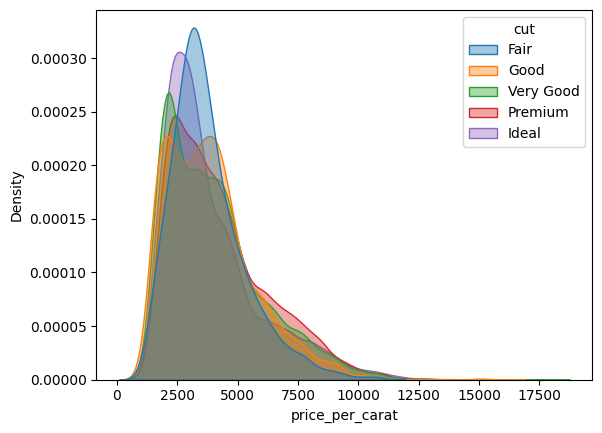

In [41]:
sns.kdeplot(data = df, x = "price_per_carat", hue = "cut", fill = True, common_norm = False, alpha = 0.4)

In [44]:
print(df.groupby('color')['price'].mean().round(2))


color
J    5323.82
I    5091.87
H    4486.67
G    3999.14
F    3724.89
E    3076.75
D    3169.95
Name: price, dtype: float64


In [45]:
print(df.groupby('color')['carat'].mean().round(2))


color
J    1.16
I    1.03
H    0.91
G    0.77
F    0.74
E    0.66
D    0.66
Name: carat, dtype: float64


In [47]:
print(df.groupby('color')['carat'].count())

color
J     2808
I     5422
H     8304
G    11292
F     9542
E     9797
D     6775
Name: carat, dtype: int64


In [59]:
df['rank'] = df.groupby('color')['price_per_carat'].transform('mean').rank(method='dense', ascending=False).astype(int)
df.head()

,carat,cut,color,clarity,depth,table,price,x,y,z,price_per_carat,rank
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43,1417.39,7
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31,1552.38,7
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31,1421.74,7
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63,1151.72,4
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75,1080.65,6


In [63]:
print(df[df['rank'] == 1][['color', 'rank']])

      color  rank
25        G     1
51        G     1
65        G     1
67        G     1
68        G     1
...     ...   ...
53889     G     1
53894     G     1
53896     G     1
53913     G     1
53929     G     1

[11292 rows x 2 columns]


In [67]:
df.groupby(['cut', 'color'])['price_per_carat'].mean().round(2).sort_values(ascending = False).head(10)

cut        color
Premium    F        4357.80
           G        4320.51
           H        4278.49
           I        4267.22
Fair       D        4244.56
Ideal      G        4164.00
Very Good  F        4142.19
Premium    J        4140.52
           D        4111.56
Very Good  I        4111.27
Name: price_per_carat, dtype: float64

In [71]:
large_diamonds = df[df['carat'] > 2.0]
print(large_diamonds['clarity'].value_counts())
print('\n\n\n\n\n')
print(large_diamonds.groupby('carat')['price'].mean().round(2))

clarity
SI2     969
SI1     458
VS2     258
I1       99
VS1      90
VVS2      6
VVS1      5
IF        4
Name: count, dtype: int64






carat
2.01    14735.13
2.02    14786.84
2.03    14710.11
2.04    14840.17
2.05    15555.40
          ...   
4.00    15984.00
4.01    15223.00
4.13    17329.00
4.50    18531.00
5.01    18018.00
Name: price, Length: 92, dtype: float64


In [81]:
prem_ideal = df[(df['cut'] == "Premium") | (df['cut'] == "Ideal")]
prem_ideal.groupby(['cut','color'])['price_per_carat'].mean().round(2).sort_values(ascending = False).head(10)

cut      color
Premium  F        4357.80
         G        4320.51
         H        4278.49
         I        4267.22
Ideal    G        4164.00
Premium  J        4140.52
         D        4111.56
Ideal    F        4097.52
Premium  E        3987.88
Ideal    H        3846.07
Name: price_per_carat, dtype: float64

In [86]:
median_prices = df.groupby('clarity')['price'].median().sort_values(ascending = False)
median_prices.head(3)

clarity
SI2    4072.0
I1     3344.0
SI1    2822.0
Name: price, dtype: float64

In [ ]:
#Ideal are sometimes lower price than Premium and Very Good cuts once size is factored in.
#Higher clarity commands a premium even if cut is not ideal
#Color and High clarity can make a lower cut more expensive than a higher cut with lower color and clarity